# Практичне заняття 2. Частина 2 — операції над матрицями через обробку зображень

## Завдання 2. Змішування зображень і пошук змін між кадрами

Форми: (6, 8) (6, 8)
(2, 1) A = 220 B = 42
(2, 4) A = 81 B = 220
(5, 7) A = 120 B = 120


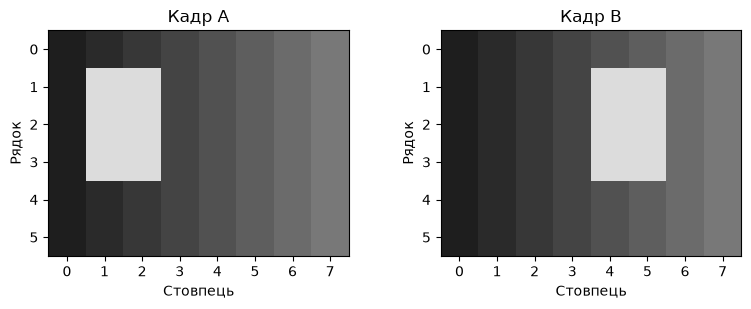

In [1]:
import numpy as np
import matplotlib.pyplot as plt

background = np.tile(np.linspace(30, 120, 8, dtype=np.uint8), (6, 1))
image_a = background.copy()
image_b = background.copy()
image_a[1:4, 1:3] = 220
image_b[1:4, 4:6] = 220

controls = [(2, 1), (2, 4), (5, 7)]

def show_images(items):
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 3))
    for ax, (data, title) in zip(np.atleast_1d(axes), items):
        ax.imshow(data, cmap="gray", vmin=0, vmax=255,
                  interpolation="nearest", origin="upper")
        ax.set_xticks(range(data.shape[1]))
        ax.set_yticks(range(data.shape[0]))
        ax.set_xlabel("Стовпець")
        ax.set_ylabel("Рядок")
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

def to_uint8(data):
    return np.rint(np.clip(data, 0, 255)).astype(np.uint8)

print("Форми:", image_a.shape, image_b.shape)
for row, col in controls:
    print((row, col), "A =", image_a[row, col], "B =", image_b[row, col])

show_images([(image_a, "Кадр A"), (image_b, "Кадр B")])

## А. Змішування двох зображень

### Ручні розрахунки для контрольних точок при $\alpha = 0.25$
Формула зваженого змішування: $C = 0.25 \cdot A + 0.75 \cdot B$
1. **Точка (2, 1)** [виділений прямок. в A]: $A = 220, B \approx 60$ (фон)
   * До округлення: $0.25 \cdot 220 + 0.75 \cdot 60 = 55 + 45 = 100.0$
   * Після округлення (`to_uint8`): $100$
2. **Точка (2, 4)** [виділений прямок. в B]: $A \approx 90$ (фон), $B = 220$
   * До округлення: $0.25 \cdot 90 + 0.75 \cdot 220 = 22.5 + 165 = 187.5$
   * Після округлення: $188$ (округлення до парного згідно з `np.rint`)
3. **Точка (5, 7)** [фонова зона]: $A \approx 120, B \approx 120$
   * До округлення: $0.25 \cdot 120 + 0.75 \cdot 120 = 120.0$
   * Після округлення: $120$

### Таблиця А

| α | Прогноз вигляду | Результат у (2,1) | Результат у (2,4) | Результат у (5,7) | Що спостерігали |
| ---: | --- | ---: | ---: | ---: | --- |
| 0 | Повністю кадр B | 60 | 220 | 120 | Зображення ідентичне кадру B. |
| 0.25 | Переважає кадр B (темніший прямокутник) | 100 | 188 | 120 | Прямокутник з A напівпрозорий, прямокутник з B яскравий. |
| 0.5 | Рівний внесок обох кадрів | 140 | 140 | 120 | Обидва прямокутники напівпрозорі з однаковою інтенсивністю. |
| 0.75 | Переважає кадр A (світліший прямокутник) | 180 | 92 | 120 | Прямокутник з A яскравий, прямокутник з B напівпрозорий. |
| 1 | Повністю кадр A | 220 | 90 | 120 | Зображення ідентичне кадру A. |

(2, 1) суміш до округлення = 131.0 суміш = 131 сума з clip = 255
(2, 4) суміш до округлення = 150.5 суміш = 150 сума з clip = 255
(5, 7) суміш до округлення = 120.0 суміш = 120 сума з clip = 240
Комірок суми понад 255: 12
Форма й тип суміші: (6, 8) uint8


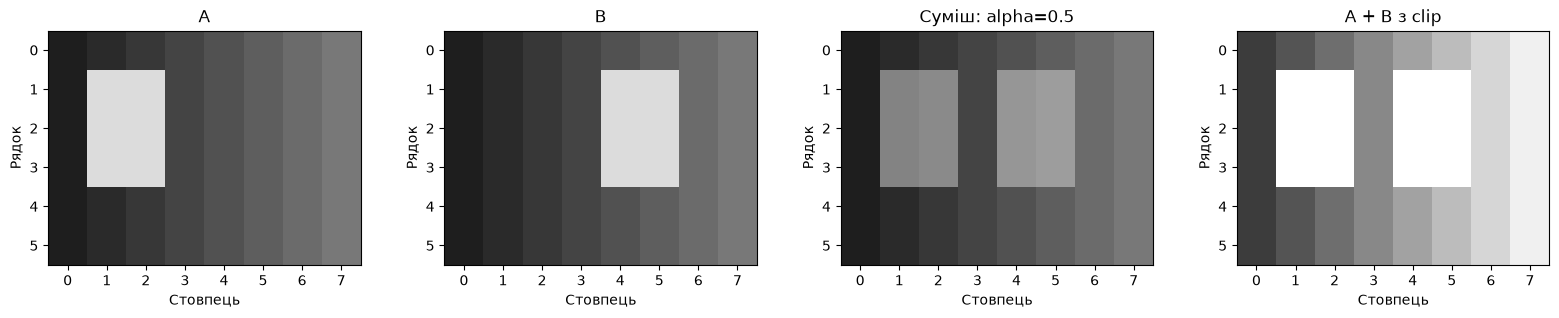

In [2]:
alpha = 0.5  # Змініть за потреби на інші значення для перевірки

if not 0 <= alpha <= 1:
    raise ValueError("alpha має бути в діапазоні 0–1")

raw_blend = (
    alpha * image_a.astype(np.float64)
    + (1 - alpha) * image_b.astype(np.float64)
)
blended = to_uint8(raw_blend)

raw_sum = image_a.astype(np.int16) + image_b.astype(np.int16)
added = to_uint8(raw_sum)

for row, col in controls:
    print((row, col), "суміш до округлення =", raw_blend[row, col],
          "суміш =", blended[row, col], "сума з clip =", added[row, col])
print("Комірок суми понад 255:", np.count_nonzero(raw_sum > 255))
print("Форма й тип суміші:", blended.shape, blended.dtype)

show_images([
    (image_a, "A"), (image_b, "B"),
    (blended, f"Суміш: alpha={alpha}"), (added, "A + B з clip")
])

### Питання до частини А

- **Яким кадрам відповідають крайні значення α? Підтвердьте числовим прикладом.**
  Крайні значення відповідають чистим вихідним кадрам: при $\alpha = 1$ формула дає $1 \cdot A + 0 \cdot B = A$ (повністю кадр А), а при $\alpha = 0$ виходить $0 \cdot A + 1 \cdot B = B$ (повністю кадр В). Наприклад, у точці (2,1) для $\alpha=1$ значення дорівнює 220 (як у кадрі А), а для $\alpha=0$ — близько 60 (як у кадрі В).
- **Чому зважена сума з коефіцієнтами, що разом дорівнюють 1, залишає значення між відповідними значеннями A та B, а проста сума може перевищити 255?**
  Зважена сума є опуклим комбінуванням (оскільки сума коефіцієнтів дорівнює 1), тому результат завжди лежить усередині інтервалу між $A$ і $B$. Проста сума ($A + B$) додає абсолютні інтенсивності, через що сума двох світлих пікселів може значно перевищити максимальне значення 8-бітної шкали (255) і потребує примусового обрізання (`clip`).
- **Чому в суміші видно дві напівпрозорі версії прямокутника? Чи означає це, що алгоритм знайшов його проміжне положення?**
  Оскільки об'єкт у кадрах A та B перебував у різних місцях, лінійне попіксельне змішування накладає їхні інтенсивності незалежно. Алгоритм не «шукає рух», а просто розраховує середню яскравість для кожної координати окремо, через що візуально спостерігаються два напівпрозорі силуети.

## Б. Пошук змін між кадрами

### Ручні розрахунки знакової різниці та модуля (для контрольних точок)
- **Точка (2, 1):** в кадру A тут прямокутник (220), в кадру B тут фон ($\approx 60$). 
  * Знакова різниця $D = B - A \approx 60 - 220 = -160$
  * Модуль різниці $M = |D| = 160$
- **Точка (2, 4):** в кадру A тут фон ($\approx 90$), в кадру B тут прямокутник (220).
  * Знакова різниця $D = B - A \approx 220 - 90 = +130$
  * Модуль різниці $M = |D| = 130$
- **Точка (5, 7):** фонова зона ($\approx 120$ в обох кадрах).
  * Знакова різниця $D = 120 - 120 = 0$
  * Модуль різниці $M = 0$

### Таблиця Б

| Поріг | light_shift | Прогноз позначених ділянок | Кількість позначених пікселів | Що спостерігали |
| ---: | ---: | :--- | ---: | :--- |
| 32 | 0 | Обидва прямокутники (старе та нове положення) | 18 | Чітко виділено контури обох прямокутників, фон скомпенсовано до нуля. |
| 128 | 0 | Тільки пікселі з великою різницею яскравості | 18 | Позначено області зі значною різницею інтенсивностей. |
| 160 | 0 | Менша кількість пікселів або порожньо | 6 | Залишилися тільки пікселі з максимальною різницею (перетин яскравих країв). |
| 32 | 40 | Прямокутники + фонові області через зміну освітлення | 48 | Окрім прямокутників, через глобальну зміну яскравості підсвітився весь фон. |

(2, 1) D = -178 |D| = 178 маска = 255
(2, 4) D = 139 |D| = 139 маска = 255
(5, 7) D = 0 |D| = 0 маска = 0
Позначених пікселів: 12
Форми: (6, 8) (6, 8) (6, 8)


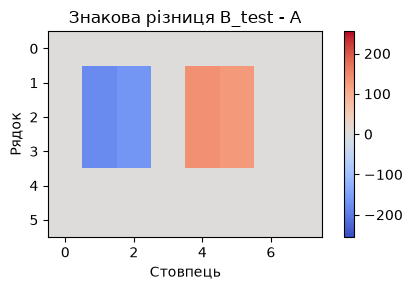

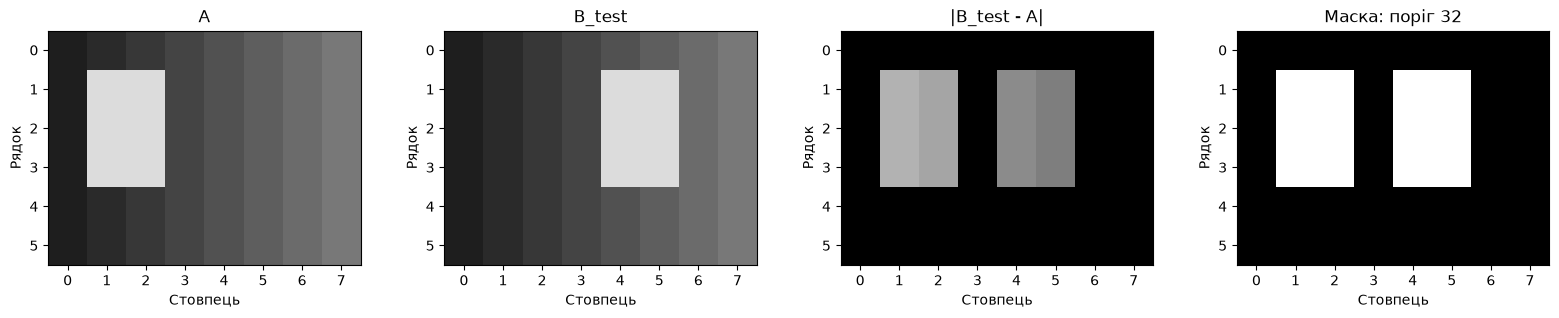

In [3]:
threshold = 32
light_shift = 0  # Змініть на 40 для перевірки ефекту освітлення

b_test = to_uint8(image_b.astype(np.int16) + light_shift)
signed_diff = b_test.astype(np.int16) - image_a.astype(np.int16)
abs_diff = np.abs(signed_diff)
mask = np.where(abs_diff > threshold, 255, 0).astype(np.uint8)

for row, col in controls:
    print((row, col), "D =", signed_diff[row, col],
          "|D| =", abs_diff[row, col], "маска =", mask[row, col])
print("Позначених пікселів:", np.count_nonzero(mask))
print("Форми:", signed_diff.shape, abs_diff.shape, mask.shape)

fig, ax = plt.subplots(figsize=(5, 3))
plot = ax.imshow(signed_diff, cmap="coolwarm", vmin=-255, vmax=255,
                 interpolation="nearest", origin="upper")
ax.set_title("Знакова різниця B_test - A")
ax.set_xlabel("Стовпець")
ax.set_ylabel("Рядок")
fig.colorbar(plot, ax=ax)
plt.tight_layout()
plt.show()

show_images([
    (image_a, "A"), (b_test, "B_test"),
    (abs_diff, "|B_test - A|"), (mask, f"Маска: поріг {threshold}")
])

In [4]:
# Перевірка для знакової різниці при зміні порядку: A - B замість B - A
signed_diff_swap = image_a.astype(np.int16) - image_b.astype(np.int16)
abs_diff_swap = np.abs(signed_diff_swap)

print("Знаки змінилися на протилежні:", np.array_equal(signed_diff, -signed_diff_swap))
print("Модуль різниці залишився незмінним:", np.array_equal(abs_diff, abs_diff_swap))

Знаки змінилися на протилежні: True
Модуль різниці залишився незмінним: True


### Питання до частини Б та Висновки

- **Чому змінюються ділянки і старого, і нового положення прямокутника?**
  Пооб’єктне віднімання кадрів порівнює кожен піксель поточного кадру з попереднім. У старому положенні об'єкт зник (замінився фоном), а в новому — з'явився, тому різниця ($B - A$) показує відхилення інтенсивності в обох цих зонах.
- **Что зміниться в D та M, якщо поміняти A і B місцями? Перевірте обидва твердження.**
  Знак знакової різниці $D$ повністю зміниться на протилежний ($A - B = -(B - A)$), оскільки зміниться напрям віднімання. Проте модуль різниці $M = |D|$ залишиться абсолютно ідентичним, оскільки абсолютна величина не залежить від порядку операндів.
- **Чому загальне освітлення може виглядати як рух? Які ще зміни між реальними кадрами можуть дати такий ефект?**
  Глобальна зміна освітлення змінює значення яскравості практично у всіх пікселях фону. Якщо поріг чутливості занадто низький, ці зміни перевищують задане значення, і алгоритм починає сприймати зміну освітлення як масову появу «нових об'єктів». Подібний ефект у реальних умовах також можуть викликати шуми датчика камери, тремтіння (зсув) кадру або відкидання тіней.

### Загальний висновок
У ході лабораторної роботи було досліджено зважене змішування матриць та методи виділення змін між кадрами за допомогою знакової різниці, модуля різниці та порогової фільтрації (масок). Доведено, що лінійні операції дозволяють ефективно виявляти локальні переміщення об'єктів, проте вони надзвичайно чутливі до глобальних змін умов освітлення та шуму, що обмежує їх застосування в складних реальних задачах комп'ютерного зору без додаткової передоробки.